<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/exercise/Listeria_timeNspace_predict_decision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
path = "/content/synthetic_listeria_weather_3x.xlsx"

In [2]:
import pandas as pd

# Excel 파일의 각 시트를 df와 tf로 읽어들이기
df = pd.read_excel(path, sheet_name='synthetic_listeria_lims_data')
tf = pd.read_excel(path, sheet_name='synthetic_weather_daily_101d')

print("df (LIMS) 행 수:", len(df))
print("tf (Weather) 행 수:", len(tf))

df (LIMS) 행 수: 3000
tf (Weather) 행 수: 5564


In [3]:
def summarize_df(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame([
        {
            'Column': col,
            'Dtype': df[col].dtype,
            'N_Unique': df[col].nunique(),
            'Null_Count': df[col].isnull().sum(),
            'Null_Ratio(%)': round(df[col].isnull().mean() * 100, 2),
            'Sample_Values': df[col].dropna().unique()[:5].tolist()
        }
        for col in df.columns
    ])

In [4]:
# summarize_df(df).to_excel("listeria_dataset_selection.xlsx")
selection_list = pd.read_excel("listeria_dataset_selection.xlsx")
selection_list[selection_list['feature 포함여부'] == 1]

,Unnamed: 0,Column,Dtype,feature 포함여부,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
2,2,judge_result,object,1,2,0,0.0,"['불검출', '검출']"
3,3,src_route,object,1,2,0,0.0,"['overseas', 'domestic']"
15,15,train_prdlst_nm_2,object,1,6,0,0.0,"['조리식품', '산양유', '아이스크림류', '수산물가공품', '치즈류']"
16,16,prduct_nm,object,1,20,0,0.0,"['수제 떡갈비 정식', '신선한 산양유 500ml', '초코 퍼지 바', '냉동 ..."
18,18,mnfctur_de,object,1,512,0,0.0,"['2025-01-26', '2026-07-29', '2026-01-25', '20..."
20,20,addr,object,1,769,0,0.0,"['충청북도 음성군 대소면 대풍산단로 88-65', '경상남도 양산시 유산공단7길 ..."
23,23,lat,float64,1,2978,0,0.0,"[36.993626, 35.345078, 35.354473, 35.3285, 36...."
24,24,lon,float64,1,2975,0,0.0,"[127.4584, 129.02031, 129.04005, 129.0041, 127..."


In [5]:
# @title **1. 예측에 필요한 컬럼만 추출하여 데이터셋 구성**
selection_list[selection_list['feature 포함여부'] == 1]['Column'].unique()
df = df[selection_list[selection_list['feature 포함여부'] == 1]['Column'].unique()].copy()
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,object,2,0,0.0,"[불검출, 검출]"
1,src_route,object,2,0,0.0,"[overseas, domestic]"
2,train_prdlst_nm_2,object,6,0,0.0,"[조리식품, 산양유, 아이스크림류, 수산물가공품, 치즈류]"
3,prduct_nm,object,20,0,0.0,"[수제 떡갈비 정식, 신선한 산양유 500ml, 초코 퍼지 바, 냉동 새우살, 자연..."
4,mnfctur_de,object,512,0,0.0,"[2025-01-26, 2026-07-29, 2026-01-25, 2025-03-1..."
5,addr,object,769,0,0.0,"[충청북도 음성군 대소면 대풍산단로 88-65, 경상남도 양산시 유산공단7길 19-..."
6,lat,float64,2978,0,0.0,"[36.993626, 35.345078, 35.354473, 35.3285, 36...."
7,lon,float64,2975,0,0.0,"[127.4584, 129.02031, 129.04005, 129.0041, 127..."


In [6]:
print(f'prduct_nm(품목명)의 종류 : {len(df["prduct_nm"].unique())}')

prduct_nm(품목명)의 종류 : 20


In [7]:
# @title 2. 국내식품만 포함(수입식품은 제외)
df = df[df['src_route'] == 'domestic']
del df['src_route']

In [8]:
# @title 중복행 확인 --> 없음
df[df.duplicated()]

,judge_result,train_prdlst_nm_2,prduct_nm,mnfctur_de,addr,lat,lon


In [9]:
# @title 검출률(불량률)
df['judge_result'].value_counts(normalize=True)

,proportion
judge_result,
불검출,0.95358
검출,0.04642


## **데이터 전처리**

### **1. addr(주소) 데이터 전처리**

In [10]:
# @title 1. 'addr' 컬럼의 문자열을 공백 기준으로 분할하여 '시도'와 '시군구'를 추출
# 데이터에 결측치나 비정상적인 주소가 있을 수 있으므로 string 타입으로 변환 후 처리
df['sido'] = df['addr'].astype(str).apply(lambda x: x.split()[0] if len(x.split()) > 0 else '')
df['sigungu'] = df['addr'].astype(str).apply(lambda x: x.split()[1] if len(x.split()) > 1 else '')
df['sido'].unique()

array(['경상남도', '경기도', '전북특별자치도', '전라남도', '충청북도', '강원특별자치도', '충청남도'],
      dtype=object)

In [11]:
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,object,2,0,0.0,"[불검출, 검출]"
1,train_prdlst_nm_2,object,6,0,0.0,"[산양유, 조리식품, 아이스크림류, 수산물가공품, 치즈류]"
2,prduct_nm,object,20,0,0.0,"[신선한 산양유 500ml, 수제 떡갈비 정식, 초코 퍼지 바, 냉동 새우살, 자연..."
3,mnfctur_de,object,492,0,0.0,"[2026-07-29, 2026-01-25, 2025-03-13, 2025-03-1..."
4,addr,object,766,0,0.0,"[경상남도 양산시 유산공단7길 19-14, 경상남도 양산시 유산공단7길 19-74,..."
5,lat,float64,2760,0,0.0,"[35.345078, 35.354473, 35.3285, 36.960964, 35...."
6,lon,float64,2759,0,0.0,"[129.02031, 129.04005, 129.0041, 127.227005, 1..."
7,sido,object,7,0,0.0,"[경상남도, 경기도, 전북특별자치도, 전라남도, 충청북도]"
8,sigungu,object,8,0,0.0,"[양산시, 안성시, 익산시, 이천시, 여수시]"


In [12]:
# @title **2. 대한 민국을 pixel로 만들어 지역정보를 구분(위도 경도 정보 --> 격자 Grid)**
import geopandas as gpd

def make_grid(df, km, lon_col='lon', lat_col='lat'):
    gdf = gpd.GeoDataFrame(
        df.copy(),
        geometry=gpd.points_from_xy(df[lon_col], df[lat_col]),
        crs='EPSG:4326'
    ).to_crs('EPSG:5179')

    size = km * 1000
    gdf['grid_x'] = (gdf.geometry.x // size).astype(int)
    gdf['grid_y'] = (gdf.geometry.y // size).astype(int)
    gdf['Grid_ID'] = gdf['grid_x'].astype(str) + '_' + gdf['grid_y'].astype(str)

    return gdf

In [13]:
df = make_grid(df, 10)

In [14]:
# @title 예측에 필요없는 Feature는 제거
df.drop(columns=['train_prdlst_nm_2', 'addr'], inplace=True)

In [15]:
summarize_df(tf)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,weather_date,object,756,0,0.0,"[2024-09-18, 2024-09-19, 2024-09-20, 2024-09-2..."
1,avg_temp,float64,400,0,0.0,"[21.5, 20.7, 21.7, 20.9, 22.7]"
2,avg_humidity,float64,617,0,0.0,"[70.6, 73.2, 83.3, 77.3, 76.5]"
3,avg_solar_rad,float64,1959,0,0.0,"[10.57, 9.72, 13.9, 12.25, 12.89]"
4,lat,float64,8,0,0.0,"[34.707359, 35.340835, 35.984201, 36.890258, 3..."
5,lon,float64,8,0,0.0,"[127.615567, 129.022362, 127.057188, 127.12576..."


## **공간과 시간 데이터 merge**
- 'synthetic_listeria_lims_data'와 'synthetic_weather_daily_101d'
> 공간데이터의 특정일자(조사일)기준 과거 100일치 기후정보
> 공간데이터의 위도와 경도 기준 가장 가까운 1곳의 기후정보와 mapping

In [16]:
# @title **시계열정보 변환 및 시간정보 구간 확인**
df['mnfctur_de'] = pd.to_datetime(df['mnfctur_de'])
tf['weather_date'] = pd.to_datetime(tf['weather_date'])

print(f'기후정보 {tf['weather_date'].max(), tf['weather_date'].min()}')
print(f'제조일자 {df['mnfctur_de'].max(), df['mnfctur_de'].min()}')

기후정보 (Timestamp('2026-10-13 00:00:00'), Timestamp('2024-09-18 00:00:00'))
제조일자 (Timestamp('2026-10-13 00:00:00'), Timestamp('2025-01-01 00:00:00'))


In [17]:
# @title tf: 일별 원시 데이터(avg_temp, avg_humidity, avg_solar_rad)의 과거 100일치를 각각 별도의 컬럼으로 merge
import numpy as np

# 1. 고유 관측소 매핑 및 유클리디안 최단 거리 station_id 부여
stations = tf[['lat', 'lon']].drop_duplicates().reset_index(drop=True)
dist = np.linalg.norm(df[['lat', 'lon']].to_numpy()[:, None] - stations.to_numpy(), axis=2)

# station_id는 tf(기상 테이블)에 있는 고유한 기상 관측 위치(lat, lon) 8곳에 0부터 7까지 순서대로 붙인 임시 고유 번호(ID)
df['station_id'] = dist.argmin(axis=1)

# 2. (station_id, weather_date) 멀티인덱스 생성 후 100일치 일괄 조회
tf_idx = (
    tf.merge(stations.rename_axis('station_id').reset_index(), on=['lat', 'lon'])
      .set_index(['station_id', 'weather_date'])[['avg_temp', 'avg_humidity', 'avg_solar_rad']]
)

lag_df = pd.concat([
    tf_idx.reindex(pd.MultiIndex.from_arrays([df['station_id'], df['mnfctur_de'] - pd.Timedelta(days=d)]))
          .reset_index(drop=True)
          .add_suffix(f'_d{d}')
    for d in range(100, 0, -1)  # 당일(D-0) 포함 시 range(99, -1, -1)
], axis=1)

df_merge = pd.concat([df.reset_index(drop=True), lag_df], axis=1)
df_merge

,judge_result,prduct_nm,mnfctur_de,lat,lon,sido,sigungu,geometry,grid_x,grid_y,...,avg_solar_rad_d4,avg_temp_d3,avg_humidity_d3,avg_solar_rad_d3,avg_temp_d2,avg_humidity_d2,avg_solar_rad_d2,avg_temp_d1,avg_humidity_d1,avg_solar_rad_d1
0,불검출,신선한 산양유 500ml,2026-07-29,35.345078,129.020310,경상남도,양산시,POINT (1138151.275 1706557.442),113,170,...,18.14,25.1,91.4,17.13,30.8,73.3,20.82,27.6,85.6,12.16
1,불검출,수제 떡갈비 정식,2026-01-25,35.354473,129.040050,경상남도,양산시,POINT (1139928.992 1707627.22),113,170,...,7.16,-0.2,44.9,7.06,-3.2,52.8,6.84,-4.0,48.8,13.11
2,불검출,초코 퍼지 바,2025-03-13,35.328500,129.004100,경상남도,양산시,POINT (1136706.076 1704696.193),113,170,...,10.96,3.8,54.5,17.27,3.9,50.7,12.07,5.4,58.1,12.68
3,불검출,냉동 새우살,2025-03-15,36.960964,127.227005,경기도,안성시,POINT (975697.541 1884761.786),97,188,...,10.95,6.5,68.7,13.73,5.7,43.7,15.97,5.9,41.7,13.01
4,불검출,자연숙성 체다치즈,2025-11-20,35.996704,127.065520,전북특별자치도,익산시,POINT (960839.604 1777855.127),96,177,...,7.70,7.7,75.7,11.69,3.6,69.8,11.56,8.5,51.5,10.28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2774,불검출,모듬 해물파전,2026-02-25,35.349886,129.037057,경상남도,양산시,POINT (1139664.925 1707114.222),113,170,...,13.57,-0.8,53.8,17.42,2.2,49.4,23.99,-0.5,53.8,15.16
2775,불검출,치킨랩 샌드위치,2026-03-25,36.978334,127.449746,충청북도,음성군,POINT (995527.328 1886655.055),99,188,...,12.53,5.5,54.9,13.57,5.4,55.7,14.26,8.8,63.6,15.44
2776,불검출,숲속산양목장 산양유,2025-04-29,36.972299,127.217325,경기도,안성시,POINT (974839.541 1886021.724),97,188,...,16.34,18.4,64.7,19.98,10.0,53.3,16.03,15.0,47.4,18.19
2777,불검출,까망베르 치즈,2026-06-25,36.873897,127.127670,충청남도,천안시,POINT (966816.847 1875133.181),96,187,...,23.97,23.7,77.9,15.51,NaN,NaN,NaN,23.6,77.6,19.48


In [18]:
# @title merged 시공간데이터 확인
print(f'df_merge 데이터 개수 {len(df_merge.columns)}')
summarize_df(df_merge).head(20)

df_merge 데이터 개수 312


,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,object,2,0,0.00,"[불검출, 검출]"
1,prduct_nm,object,20,0,0.00,"[신선한 산양유 500ml, 수제 떡갈비 정식, 초코 퍼지 바, 냉동 새우살, 자연..."
2,mnfctur_de,datetime64[ns],492,0,0.00,"[2026-07-29 00:00:00, 2026-01-25 00:00:00, 202..."
3,lat,float64,2760,0,0.00,"[35.345078, 35.354473, 35.3285, 36.960964, 35...."
4,lon,float64,2759,0,0.00,"[129.02031, 129.04005, 129.0041, 127.227005, 1..."
5,sido,object,7,0,0.00,"[경상남도, 경기도, 전북특별자치도, 전라남도, 충청북도]"
6,sigungu,object,8,0,0.00,"[양산시, 안성시, 익산시, 이천시, 여수시]"
7,geometry,geometry,2779,0,0.00,"[POINT (1138151.2746762815 1706557.441830074),..."
8,grid_x,int64,11,0,0.00,"[113, 97, 96, 99, 98]"
9,grid_y,int64,9,0,0.00,"[170, 188, 177, 191, 163]"


- **총 308개가 정상**
> **station_id 포함 df 컬럼 수 7개 + 과거 100일의 3개 기후정보 300개 + station_id(최근접 위경도 정보, neareat neighbor =1)**

In [19]:
# @title 결측치가 존재하는 Feature(기후정보) 이름(300 개) 추출하고 결측치 대체(Imputation)
summary_df = summarize_df(df_merge)
null_col = summary_df[summary_df['Null_Count'] > 0]['Column'].unique()
len(null_col)

300

In [20]:
from tqdm import tqdm

# null_col에 포함된 컬럼들의 원본 기상 변수 접두사만 추출합니다.
base_features = set()
for col in null_col:
    for base in ['avg_temp', 'avg_humidity', 'avg_solar_rad']:
        if col.startswith(base):
            base_features.add(base)

# 추출된 기본 변수들에 대해 결측치 대체(Imputation)를 진행합니다.
for col in tqdm(base_features):
    cols = [f'{col}_d{d}' for d in range(100, 0, -1)]  # 과거(d100) -> 최근(d1) 순서
    sub = df_merge[cols]

    df_merge[cols] = (
        sub.fillna(sub.T.rolling(3, min_periods=1, closed='left').mean().T)
           .ffill(axis=1)
           .bfill(axis=1)
    )

100%|██████████| 3/3 [00:01<00:00,  2.38it/s]


In [21]:
# @title 결측치가 없는 것을 확인
assert (summarize_df(df_merge)['Null_Count'] > 0).sum() == 0

In [22]:
summarize_df(df_merge)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,object,2,0,0.0,"[불검출, 검출]"
1,prduct_nm,object,20,0,0.0,"[신선한 산양유 500ml, 수제 떡갈비 정식, 초코 퍼지 바, 냉동 새우살, 자연..."
2,mnfctur_de,datetime64[ns],492,0,0.0,"[2026-07-29 00:00:00, 2026-01-25 00:00:00, 202..."
3,lat,float64,2760,0,0.0,"[35.345078, 35.354473, 35.3285, 36.960964, 35...."
4,lon,float64,2759,0,0.0,"[129.02031, 129.04005, 129.0041, 127.227005, 1..."
...,...,...,...,...,...,...
307,avg_humidity_d2,float64,446,0,0.0,"[73.3, 52.8, 50.7, 43.7, 69.8]"
308,avg_solar_rad_d2,float64,690,0,0.0,"[20.82, 6.84, 12.07, 15.97, 11.56]"
309,avg_temp_d1,float64,377,0,0.0,"[27.6, -4.0, 5.4, 5.9, 8.5]"
310,avg_humidity_d1,float64,446,0,0.0,"[85.6, 48.8, 58.1, 41.7, 51.5]"


In [23]:
# @title 기후정보에 대한 요약 통계 추가 (100 동안 평균 최고, 최저)
# 1. 관측소 매핑
stations = tf[['lat', 'lon']].drop_duplicates().reset_index(drop=True)
df_merge['station_id'] = np.linalg.norm(
    df_merge[['lat', 'lon']].to_numpy()[:, None] - stations.to_numpy(), axis=2
).argmin(axis=1)

# 2. 전체 날짜 격자 생성 (제조일 당일이 비어서 merge 실패하는 현상 방지)
all_dates = pd.date_range(
    min(tf['weather_date'].min(), df_merge['mnfctur_de'].min()),
    max(tf['weather_date'].max(), df_merge['mnfctur_de'].max()),
    freq='D'
)
full_idx = pd.MultiIndex.from_product([range(len(stations)), all_dates], names=['station_id', 'weather_date'])

tf_grid = (
    tf.merge(stations.rename_axis('station_id').reset_index(), on=['lat', 'lon'])
      .drop_duplicates(['station_id', 'weather_date'])
      .set_index(['station_id', 'weather_date'])[['avg_temp', 'avg_humidity', 'avg_solar_rad']]
      .reindex(full_idx)
      .sort_index()
)

# 3. 인덱스 초기화 후 DatetimeIndex를 위해 weather_date를 인덱스로 설정 후 그룹화 연산
tf_grid_reset = tf_grid.reset_index(level='station_id')
tf_roll = (
    tf_grid_reset.groupby('station_id')
                 .rolling('100D', closed='left', min_periods=1)
                 .agg(['mean', 'max', 'min'])
)

# rolling 결과 생성된 멀티인덱스는 (station_id, weather_date) 형태를 취하므로, 이 구성을 그대로 살려 컬럼명만 변경해 줍니다.
tf_roll.columns = [f'{c}_{stat}_100d' for c, stat in tf_roll.columns]

# 4. df_merge와 병합 (tf_roll의 멀티인덱스를 reset_index()하면 'station_id'와 'weather_date'가 모두 컬럼으로 복구됩니다.)
df_final = df_merge.merge(
    tf_roll.reset_index(),
    left_on=['station_id', 'mnfctur_de'],
    right_on=['station_id', 'weather_date'],
    how='left'
).drop(columns=['weather_date'])

In [24]:
# @title 결측치가 없는 것을 확인
assert (summarize_df(df_merge)['Null_Count'] > 0).sum() == 0

In [25]:
summarize_df(df_final).head(15)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,object,2,0,0.0,"[불검출, 검출]"
1,prduct_nm,object,20,0,0.0,"[신선한 산양유 500ml, 수제 떡갈비 정식, 초코 퍼지 바, 냉동 새우살, 자연..."
2,mnfctur_de,datetime64[ns],492,0,0.0,"[2026-07-29 00:00:00, 2026-01-25 00:00:00, 202..."
3,lat,float64,2760,0,0.0,"[35.345078, 35.354473, 35.3285, 36.960964, 35...."
4,lon,float64,2759,0,0.0,"[129.02031, 129.04005, 129.0041, 127.227005, 1..."
5,sido,object,7,0,0.0,"[경상남도, 경기도, 전북특별자치도, 전라남도, 충청북도]"
6,sigungu,object,8,0,0.0,"[양산시, 안성시, 익산시, 이천시, 여수시]"
7,geometry,geometry,2779,0,0.0,"[POINT (1138151.2746762815 1706557.441830074),..."
8,grid_x,int64,11,0,0.0,"[113, 97, 96, 99, 98]"
9,grid_y,int64,9,0,0.0,"[170, 188, 177, 191, 163]"


In [26]:
len(df_final)

2779

In [27]:
df_final.drop(columns=['prduct_nm', 'lat', 'lon', 'geometry', 'Grid_ID', 'station_id'],
        inplace=True)

In [33]:
# df_final = df_final.set_index('mnfctur_de')
print(df_final.index)
summarize_df(df_final).head(10)

DatetimeIndex(['2026-07-29', '2026-01-25', '2025-03-13', '2025-03-15',
               '2025-11-20', '2025-09-10', '2026-09-03', '2025-04-25',
               '2025-06-06', '2025-03-12',
               ...
               '2025-12-23', '2025-09-10', '2026-01-12', '2026-05-22',
               '2025-10-15', '2026-02-25', '2026-03-25', '2025-04-29',
               '2026-06-25', '2026-08-27'],
              dtype='datetime64[ns]', name='mnfctur_de', length=2779, freq=None)


,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,object,2,0,0.0,"[불검출, 검출]"
1,sido,object,7,0,0.0,"[경상남도, 경기도, 전북특별자치도, 전라남도, 충청북도]"
2,sigungu,object,8,0,0.0,"[양산시, 안성시, 익산시, 이천시, 여수시]"
3,grid_x,int64,11,0,0.0,"[113, 97, 96, 99, 98]"
4,grid_y,int64,9,0,0.0,"[170, 188, 177, 191, 163]"
5,avg_temp_d100,float64,320,0,0.0,"[13.8, 16.4, 1.0, 1.4, 28.1]"
6,avg_humidity_d100,float64,401,0,0.0,"[61.6, 54.5, 42.0, 51.5, 76.9]"
7,avg_solar_rad_d100,float64,664,0,0.0,"[16.85, 6.62, 6.4, 8.05, 15.42]"
8,avg_temp_d99,float64,332,0,0.0,"[14.4, 11.8, 2.4, -3.1, 30.9]"
9,avg_humidity_d99,float64,400,0,0.0,"[53.6, 50.3, 46.2, 56.4, 76.4]"


In [36]:
# @title 데이터전처리 후 알고리즘과 pipe 만들기
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score
)
from xgboost import XGBClassifier

# 1. 시간순(오름차순) 정렬 (가장 최근 데이터가 뒷부분 검증 세트로 가도록 보장)
df_sorted = df_final.sort_index(ascending=True).copy()

# 2. 타겟(y) 및 피처(X) 분리
y = (df_sorted['judge_result'] == '검출').astype(int)

drop_cols = [
    'judge_result', 'geometry', 'lat', 'lon',
    'grid_x', 'grid_y', 'Grid_ID', 'station_id', 'addr', 'weather_date'
]
X = df_sorted.drop(columns=[c for c in drop_cols if c in df_sorted.columns]).copy()
X['mnfctur_month'] = df_sorted.index.month

# 3. 최근 데이터를 최종 Hold-out 검증 세트로 분리 (최근 20%)
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"학습 기간: {X_train.index.min().date()} ~ {X_train.index.max().date()} ({len(X_train)}건, 검출 비율: {y_train.mean():.2%})")
print(f"검증 기간: {X_test.index.min().date()} ~ {X_test.index.max().date()} ({len(X_test)}건, 검출 비율: {y_test.mean():.2%})")

# 4. ColumnTransformer 구성 (수치형 스케일링 + 범주형 원핫인코딩)
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X_train.select_dtypes(exclude=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ],
    remainder='drop'
)

# 5. Balanced 가중치 계산 및 XGBoost Pipeline 구성
base_pos_weight = (y_train == 0).sum() / max((y_train == 1).sum(), 1)

pipe = Pipeline([
    ('prep', preprocessor),
    ('xgb', XGBClassifier(
        random_state=42,
        n_jobs=-1,
        eval_metric='aucpr',                 # 내부 평가 지표도 PR-AUC로 설정
        scale_pos_weight=base_pos_weight     # 불균형 클래스 가중치 균형화
    ))
])

# 6. TimeSeriesSplit 및 RandomizedSearchCV (scoring='average_precision' -> PR-AUC)
tscv = TimeSeriesSplit(n_splits=5)

param_dist = {
    'xgb__n_estimators': [100, 200, 300, 500],
    'xgb__max_depth': [3, 4, 5, 6, 8],
    'xgb__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'xgb__subsample': [0.7, 0.8, 0.9, 1.0],
    'xgb__colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'xgb__min_child_weight': [1, 3, 5, 10],
    'xgb__gamma': [0, 0.1, 0.3, 0.5],
    # 클래스 불균형 가중치(balanced 비율)도 함께 튜닝
    'xgb__scale_pos_weight': [
        base_pos_weight * 0.5,
        base_pos_weight,
        base_pos_weight * 1.5,
        np.sqrt(base_pos_weight)
    ]
}

random_search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_dist,
    n_iter=30,
    cv=tscv,
    scoring='average_precision',  # PR-AUC 스코어링
    n_jobs=-1,
    random_state=42,
    verbose=2
)

# 7. 하이퍼파라미터 튜닝 실행
random_search.fit(X_train, y_train)

print("\n최적 하이퍼파라미터:", random_search.best_params_)
print(f"TimeSeries CV 최고 PR-AUC: {random_search.best_score_:.4f}")

# 8. 최근 데이터(X_test) 예측 및 PR 곡선 기반 최적 임계값(Balanced Threshold) 적용
best_model = random_search.best_estimator_
y_prob = best_model.predict_proba(X_test)[:, 1]

# 학습 세트 기준 F1 최대화 임계값 탐색 (데이터 누수 방지)
train_prob = best_model.predict_proba(X_train)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train, train_prob)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / np.maximum(precisions[:-1] + recalls[:-1], 1e-8)
best_thresh = thresholds[np.argmax(f1_scores)]

y_pred_balanced = (y_prob >= best_thresh).astype(int)

print(f"\n[최근 데이터 검증 결과] (적용 임계값: {best_thresh:.4f})")
print(f"PR-AUC: {average_precision_score(y_test, y_prob):.4f} | ROC-AUC: {roc_auc_score(y_test, y_prob):.4f} | Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred_balanced):.4f}")
print(classification_report(y_test, y_pred_balanced, target_names=['불검출', '검출']))

학습 기간: 2025-01-01 ~ 2026-05-22 (2223건, 검출 비율: 4.18%)
검증 기간: 2026-05-23 ~ 2026-10-13 (556건, 검출 비율: 6.47%)
Fitting 5 folds for each of 30 candidates, totalling 150 fits

최적 하이퍼파라미터: {'xgb__subsample': 0.7, 'xgb__scale_pos_weight': np.float64(4.785731480813734), 'xgb__n_estimators': 500, 'xgb__min_child_weight': 10, 'xgb__max_depth': 3, 'xgb__learning_rate': 0.01, 'xgb__gamma': 0.3, 'xgb__colsample_bytree': 1.0}
TimeSeries CV 최고 PR-AUC: 0.0999

[최근 데이터 검증 결과] (적용 임계값: 0.3737)
PR-AUC: 0.1143 | ROC-AUC: 0.5372 | Balanced Accuracy: 0.5000
              precision    recall  f1-score   support

         불검출       0.94      1.00      0.97       520
          검출       0.00      0.00      0.00        36

    accuracy                           0.94       556
   macro avg       0.47      0.50      0.48       556
weighted avg       0.87      0.94      0.90       556



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


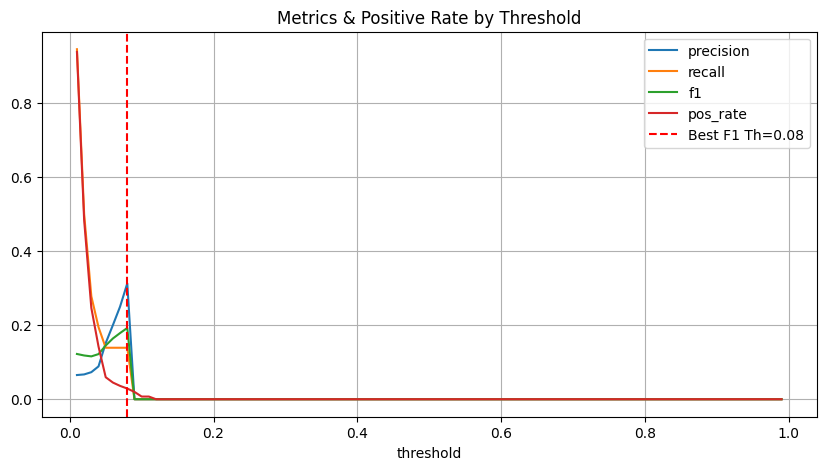

,threshold,precision,recall,f1,pos_rate
9,0.1,0.0,0.0,0.0,0.007
19,0.2,0.0,0.0,0.0,0.000
29,0.3,0.0,0.0,0.0,0.000
39,0.4,0.0,0.0,0.0,0.000
49,0.5,0.0,0.0,0.0,0.000
59,0.6,0.0,0.0,0.0,0.000
69,0.7,0.0,0.0,0.0,0.000
79,0.8,0.0,0.0,0.0,0.000
89,0.9,0.0,0.0,0.0,0.000


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

y_prob = best_model.predict_proba(X_test)[:, 1]
ths = np.linspace(0.01, 0.99, 99)

df_th = pd.DataFrame([
    {
        'threshold': t,
        'precision': precision_score(y_test, y_prob >= t, zero_division=0),
        'recall': recall_score(y_test, y_prob >= t, zero_division=0),
        'f1': f1_score(y_test, y_prob >= t, zero_division=0),
        'pos_rate': (y_prob >= t).mean()
    }
    for t in ths
])

best_th = df_th.loc[df_th['f1'].idxmax(), 'threshold']

ax = df_th.plot(x='threshold', figsize=(10, 5), grid=True, title='Metrics & Positive Rate by Threshold')
ax.axvline(best_th, color='red', linestyle='--', label=f'Best F1 Th={best_th:.2f}')
ax.legend()
plt.show()

display(df_th[df_th['threshold'].round(2).isin(np.round(np.arange(0.1, 1.0, 0.1), 2))].round(3))